# 002 多类线性 SVM：题目要求

**需要完成：** 实现循环和向量化 hinge 损失及梯度；执行数值梯度检查；mini-batch SGD 训练；仅用验证集调参；测试与可视化分类权重；回答不可导点与权重解释问题。

**实验范围与验收：** 训练/验证划分 49000/1000，测试按本 notebook 的 1000 张子集评估。

**阅读顺序：** 先阅读原题和代码块前的中文解析，再检查实际输出与问题记录；若本题包含方法二，它紧随对应方法一，使用独立状态。方法一不得依赖方法二才能运行。

**课程参考：** [CS231n 课程资料](https://cs231n.github.io/)。本题的实现、检查和实验结果按下文顺序记录。


# 多类支持向量机练习

*完成并连同作业上交你完整的工作表(包括其输出及工作表外的任何支持代码),更多详情请参见课程网站上的[作业页面](http://vision.stanford.edu/teaching/cs231n/assignments.html)。*

在这个练习中，你将:
    
- 为SVM实现一个全向量化的**损失函数**
- 实现其**解析梯度**的全向量化表达式
- 使用数值梯度**检查你的实现**
- 使用验证集**调整学习率和正则化**强度
- 用**SGD优化**损耗函数
- **可视化**最后学习的重量

**本段解析**

固定 NumPy 与 Python 随机种子为 231，读取共享数据配置，并限制 BLAS 线程数量。这样既能运行验证初始化和抽样，也能避免小矩阵运算中线程调度开销；原始数据文件保持不变。

In [1]:
# 固定实验起点；读取共享数据路径；限制 BLAS 线程，避免多线程调度开销。
import os, sys, random
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
from study_runtime import data_path
import numpy as np
from threadpoolctl import threadpool_limits
_blas_limit = threadpool_limits(limits=4)
np.random.seed(231)
random.seed(231)


**本段解析**

导入本作业的数组、数据读取和绘图工具。这里仅建立计算与显示环境，线性 SVM 的损失和梯度实现位于 cs231n/classifiers/linear_svm.py，后续单元将先检查它再进入训练。

In [2]:
# Run some setup code for this notebook.

import random
import numpy as np
from cs231n.data_utils import load_CIFAR10
import matplotlib.pyplot as plt

# This is a bit of magic to make matplotlib figures appear inline in the
# notebook rather than in a new window.
%matplotlib inline
plt.rcParams['figure.figsize'] = (12.0, 9.0) # set default size of plots
plt.rcParams['image.interpolation'] = 'nearest'
plt.rcParams['image.cmap'] = 'gray'

# Some more magic so that the notebook will reload external python modules;
# see http://stackoverflow.com/questions/1907993/autoreload-of-modules-in-ipython
%load_ext autoreload
%autoreload 2

## CIFAR-10 Data Loading and Preprocessing

**本段解析**

读取经过校验的共享 CIFAR-10 数据，返回 HWC 图像数组和整数标签。打印形状检查批次拼接及标签对齐，数据路径统一管理，不因 SVM 实验再次下载。

In [3]:
# Load the raw CIFAR-10 data.
cifar10_dir = 'cs231n/datasets/cifar-10-batches-py'
X_train, y_train, X_test, y_test = load_CIFAR10(cifar10_dir)

# As a sanity check, we print out the size of the training and test data.
print ('Training data shape: ', X_train.shape)
print ('Training labels shape: ', y_train.shape)
print ('Test data shape: ', X_test.shape)
print ('Test labels shape: ', y_test.shape)

Training data shape:  (50000, 32, 32, 3)
Training labels shape:  (50000,)
Test data shape:  (10000, 32, 32, 3)
Test labels shape:  (10000,)


**本段解析**

从训练集按十个类别抽取样例并显示，检查输入图像是否正常。展示用的随机抽样不改变训练、验证和测试划分。

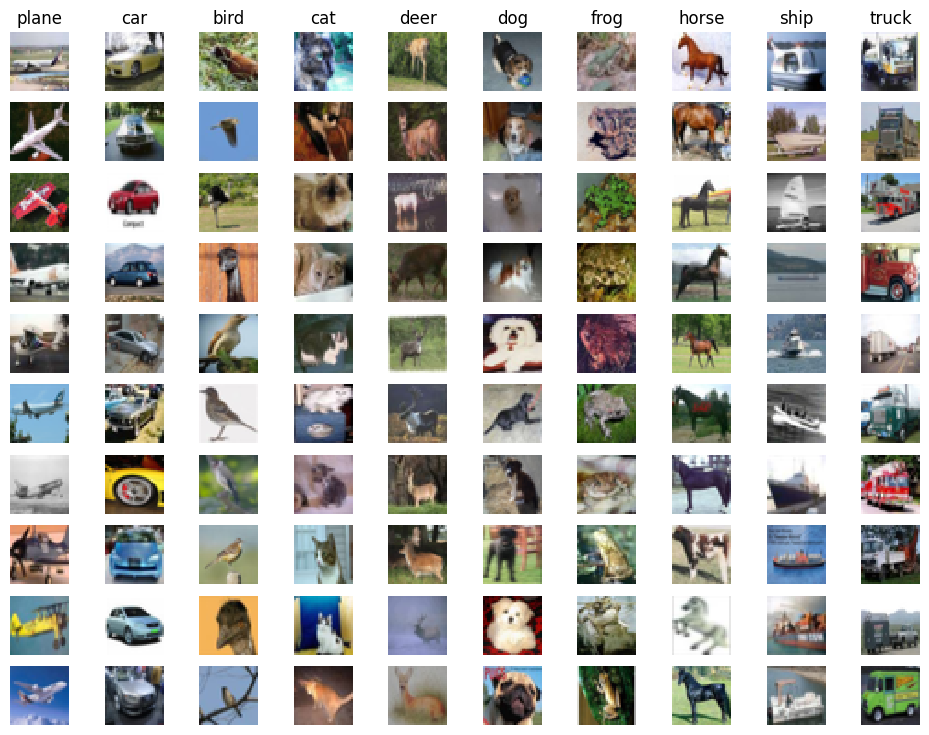

In [4]:
# Visualize some examples from the dataset.
# We show a few examples of training images from each class.
classes = ['plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
num_classes = len(classes)
samples_per_class = 10
for y, cls in enumerate(classes):
    idxs = np.flatnonzero(y_train == y)
    idxs = np.random.choice(idxs, samples_per_class, replace=False)
    for i, idx in enumerate(idxs):
        plt_idx = i * num_classes + y + 1
        plt.subplot(samples_per_class, num_classes, plt_idx)
        plt.imshow(X_train[idx].astype('uint8'))
        plt.axis('off')
        if i == 0:
            plt.title(cls)
plt.show()

**本段解析**

将原训练集前 49000 张作为训练，随后 1000 张作为验证；测试集按题目取 1000 张，并从训练部分抽取 500 张开发样本用于快速梯度检查。标签与图像同步索引，开发集不能混入独立验证集。

In [5]:
# Split the data into train, val, and test sets. In addition we will
# create a small development set as a subset of the training data;
# we can use this for development so our code runs faster.
num_training = 49000
num_validation = 1000
num_test = 1000
num_dev = 500

# Our validation set will be num_validation points from the original
# training set.
mask = range(num_training, num_training + num_validation)
X_val = X_train[mask]
y_val = y_train[mask]

# Our training set will be the first num_train points from the original
# training set.
mask = range(num_training)
X_train = X_train[mask]
y_train = y_train[mask]

# We will also make a development set, which is a small subset of
# the training set.
mask = np.random.choice(num_training, num_dev, replace=False)
X_dev = X_train[mask]
y_dev = y_train[mask]

# We use the first num_test points of the original test set as our
# test set.
mask = range(num_test)
X_test = X_test[mask]
y_test = y_test[mask]

print ('Train data shape: ', X_train.shape)
print ('Train labels shape: ', y_train.shape)
print ('Validation data shape: ', X_val.shape)
print ('Validation labels shape: ', y_val.shape)
print ('Test data shape: ', X_test.shape)
print ('Test labels shape: ', y_test.shape)

Train data shape:  (49000, 32, 32, 3)
Train labels shape:  (49000,)
Validation data shape:  (1000, 32, 32, 3)
Validation labels shape:  (1000,)
Test data shape:  (1000, 32, 32, 3)
Test labels shape:  (1000,)


**本段解析**

把三个数据划分及开发集从 HWC 图像变为每行 3072 维特征矩阵。后续线性模型输入 X 的列与权重 W 的行一一对应，形状不一致会直接导致矩阵乘法失败。

In [6]:
# Preprocessing: reshape the image data into rows
X_train = np.reshape(X_train, (X_train.shape[0], -1))
X_val = np.reshape(X_val, (X_val.shape[0], -1))
X_test = np.reshape(X_test, (X_test.shape[0], -1))
X_dev = np.reshape(X_dev, (X_dev.shape[0], -1))

# As a sanity check, print out the shapes of the data
print ('Training data shape: ', X_train.shape)
print ('Validation data shape: ', X_val.shape)
print ('Test data shape: ', X_test.shape)
print ('dev data shape: ', X_dev.shape)

Training data shape:  (49000, 3072)
Validation data shape:  (1000, 3072)
Test data shape:  (1000, 3072)
dev data shape:  (500, 3072)


**本段解析**

仅使用训练矩阵沿样本轴求均值，得到 3072 维平均图像，并显示其颜色结构。这个均值是预处理参数，应从训练集估计后固定，不能在验证集或测试集上重新估计。

[130.64189796 135.98173469 132.47391837 130.05569388 135.34804082
 131.75402041 130.96055102 136.14328571 132.47636735 131.48467347
 136.58542857 132.78293878 132.094      137.14008163 133.177
 132.76759184 137.77767347 133.70602041 133.29373469 138.21244898
 134.08095918 133.8194898  138.67242857 134.45065306 134.41440816
 139.20602041 134.94291837 134.85138776 139.55787755 135.22173469
 135.14859184 139.86202041 135.43195918 135.31191837 140.00128571
 135.5654898  135.52016327 140.17377551 135.71577551 135.54589796
 140.17855102 135.71587755 135.55465306 140.15055102 135.69661224
 135.52167347 140.08855102 135.63073469 135.4325102  140.00187755
 135.47902041 135.39046939 139.9555102  135.43814286 135.36910204
 139.93644898 135.44763265 135.25942857 139.84093878 135.34230612
 134.98636735 139.59830612 135.08753061 134.84430612 139.51479592
 135.07187755 134.69879592 139.39363265 134.9984898  134.41985714
 139.19859184 134.81940816 133.94426531 138.85381633 134.52361224
 133.49555102 1

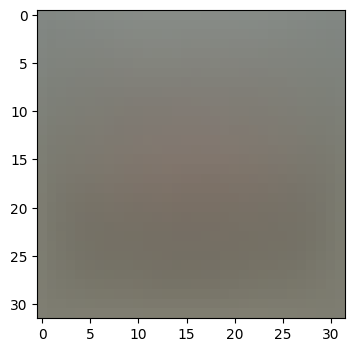

In [7]:
# Preprocessing: subtract the mean image
# first: compute the image mean based on the training data
mean_image = np.mean(X_train, axis=0)
print (mean_image[:100]) # print a few of the elements
plt.figure(figsize=(4,4))
plt.imshow(mean_image.reshape((32,32,3)).astype('uint8')) # visualize the mean image
plt.show()

**本段解析**

从训练、验证、测试和开发样本中减去同一个训练均值，使特征以训练分布中心为原点。所有划分采用相同变换；数组在本 notebook 内修改，不写回共享原始数据。

In [8]:
# second: subtract the mean image from train and test data
X_train -= mean_image
X_val -= mean_image
X_test -= mean_image
X_dev -= mean_image

**本段解析**

给每行特征追加常数 1，把偏置并入权重矩阵最后一行。输入维数由 3072 变为 3073，模型通过一次 XW 同时计算线性项和偏置；可视化权重时需要去除这一行。

In [9]:
# third: append the bias dimension of ones (i.e. bias trick) so that our SVM
# only has to worry about optimizing a single weight matrix W.
X_train = np.hstack([X_train, np.ones((X_train.shape[0], 1))])
X_val = np.hstack([X_val, np.ones((X_val.shape[0], 1))])
X_test = np.hstack([X_test, np.ones((X_test.shape[0], 1))])
X_dev = np.hstack([X_dev, np.ones((X_dev.shape[0], 1))])

print (X_train.shape, X_val.shape, X_test.shape, X_dev.shape)

(49000, 3073) (1000, 3073) (1000, 3073) (500, 3073)


## SVM 分类器

本节的代码将全部写在**cs231n/classifiers/ linear_svm .py**内

函数`svm_loss_naive`，使用for循环来评估多类SVM损失函数。

**本段解析**

随机初始化较小的 W，在开发集上调用带显式循环的多类 hinge 损失。每个错误类别的 margin 为 s_j−s_y+1，大于零才计入损失；输出标量损失和与 W 同形状的梯度。

In [10]:
# Evaluate the naive implementation of the loss we provided for you:
from cs231n.classifiers.linear_svm import svm_loss_naive
import time

# generate a random SVM weight matrix of small numbers
W = np.random.randn(3073, 10) * 0.0001 

loss, grad = svm_loss_naive(W, X_dev, y_dev, 0.00001)
print ('loss: %f' % (loss, ))

loss: 9.075699


从上面的函数返回的`grad`现在全部为零。推导并实现SVM损失函数的梯度，并将其在函数`svm_loss_naive`中实现

为了检查是否正确地实现了梯度，可以数值地估计损失函数的梯度，并将数值估计与计算的梯度进行比较

**本段解析**

分别在无正则化和有正则化条件下，对随机参数位置计算中心差分，与解析梯度比较。hinge 的折点不可导，少量靠近 margin=0 的位置可能出现差异，需要结合扰动尺度与位置判断，而不是简单忽略全部误差。

In [11]:
# Once you've implemented the gradient, recompute it with the code below
# and gradient check it with the function we provided for you

# Compute the loss and its gradient at W.
loss, grad = svm_loss_naive(W, X_dev, y_dev, 0.0)

# Numerically compute the gradient along several randomly chosen dimensions, and
# compare them with your analytically computed gradient. The numbers should match
# almost exactly along all dimensions.
from cs231n.gradient_check import grad_check_sparse
f = lambda w: svm_loss_naive(w, X_dev, y_dev, 0.0)[0]
grad_numerical = grad_check_sparse(f, W, grad)

# do the gradient check once again with regularization turned on
# you didn't forget the regularization gradient did you?
loss, grad = svm_loss_naive(W, X_dev, y_dev, 1e2)
f = lambda w: svm_loss_naive(w, X_dev, y_dev, 1e2)[0]
grad_numerical = grad_check_sparse(f, W, grad)

numerical: 6.885097 analytic: 6.885097, relative error: 2.774870e-11
numerical: -1.487470 analytic: -1.487470, relative error: 2.469292e-10
numerical: -22.899852 analytic: -22.899852, relative error: 1.124806e-11


numerical: -30.836645 analytic: -30.836645, relative error: 1.292648e-11
numerical: 18.118437 analytic: 18.118437, relative error: 2.485055e-12
numerical: -16.912062 analytic: -16.912062, relative error: 1.542490e-11


numerical: -0.037108 analytic: -0.037108, relative error: 4.350246e-09
numerical: 1.763900 analytic: 1.763900, relative error: 1.127878e-11
numerical: -11.313578 analytic: -11.313578, relative error: 8.747321e-12


numerical: -21.224263 analytic: -21.224263, relative error: 1.112795e-11
numerical: -7.729549 analytic: -7.729549, relative error: 1.096579e-11


numerical: 34.373350 analytic: 34.373350, relative error: 1.128448e-11
numerical: 25.984941 analytic: 25.984941, relative error: 1.464081e-11
numerical: 12.656173 analytic: 12.656173, relative error: 1.725433e-11


numerical: -36.077415 analytic: -36.077415, relative error: 5.698437e-12
numerical: -4.175940 analytic: -4.175940, relative error: 4.036037e-11
numerical: -23.094880 analytic: -23.094880, relative error: 1.615236e-11


numerical: -12.516596 analytic: -12.516596, relative error: 2.855915e-11
numerical: 19.460984 analytic: 19.460984, relative error: 7.404277e-12
numerical: 0.755067 analytic: 0.755067, relative error: 1.900445e-12


### Inline Question 1：为什么 SVM 数值梯度有时不完全匹配？

**我的分析：** hinge 项 max(0, margin) 在 margin=0 处不可导。当中心差分的两个扰动跨过折点时，它测到的是两侧函数变化的平均斜率，不一定等于实现选取的一侧次梯度。一维例子是 max(0,x) 在 x=0 附近：中心差分得到 0.5，而程序可能约定梯度为 0。应检查误差位置、margin 与步长，不能因为可能存在折点就忽略成片或系统性的梯度错误。

**本段解析**

在完全相同的 W、输入和标签上比较循环与向量化损失及计时。向量化实现一次计算全部 margin、清零正确类别并聚合；两者损失差应接近浮点误差。

In [12]:
# Next implement the function svm_loss_vectorized; for now only compute the loss;
# we will implement the gradient in a moment.
tic = time.time()
loss_naive, grad_naive = svm_loss_naive(W, X_dev, y_dev, 0.00001)
toc = time.time()
print ('Naive loss: %e computed in %fs' % (loss_naive, toc - tic))

from cs231n.classifiers.linear_svm import svm_loss_vectorized
tic = time.time()
loss_vectorized, _ = svm_loss_vectorized(W, X_dev, y_dev, 0.00001)
toc = time.time()
print ('Vectorized loss: %e computed in %fs' % (loss_vectorized, toc - tic))

# The losses should match but your vectorized implementation should be much faster.
print ('difference: %f' % (loss_naive - loss_vectorized))

Naive loss: 9.075699e+00 computed in 0.035889s
Vectorized loss: 9.075699e+00 computed in 0.002489s
difference: 0.000000


**本段解析**

进一步比较两种实现的梯度矩阵。错误类别的正 margin 贡献 +x，正确类别贡献负的有效错误类别数乘 x；输出梯度差范数与耗时，用于确认加速没有改变优化方向。

In [13]:
# Complete the implementation of svm_loss_vectorized, and compute the gradient
# of the loss function in a vectorized way.

# The naive implementation and the vectorized implementation should match, but
# the vectorized version should still be much faster.
tic = time.time()
_, grad_naive = svm_loss_naive(W, X_dev, y_dev, 0.00001)
toc = time.time()
print ('Naive loss and gradient: computed in %fs' % (toc - tic))

tic = time.time()
_, grad_vectorized = svm_loss_vectorized(W, X_dev, y_dev, 0.00001)
toc = time.time()
print ('Vectorized loss and gradient: computed in %fs' % (toc - tic))

# The loss is a single number, so it is easy to compare the values computed
# by the two implementations. The gradient on the other hand is a matrix, so
# we use the Frobenius norm to compare them.
difference = np.linalg.norm(grad_naive - grad_vectorized, ord='fro')
print ('difference: %f' % difference)

Naive loss and gradient: computed in 0.035851s
Vectorized loss and gradient: computed in 0.001029s
difference: 0.000000


### 随机梯度下降
我们现在有了矢量化的有效的损失表达式，梯度和我们的梯度匹配的数值梯度。因此，我们准备做SGD以减少损失。

**本段解析**

实例化 LinearSVM，随机抽取 mini-batch，重复计算损失和梯度并按 W←W−η∇W 更新。训练函数返回每次迭代损失；这一步先用固定配置验证整个训练回路能工作。

In [14]:
# In the file linear_classifier.py, implement SGD in the function
# LinearClassifier.train() and then run it with the code below.
from cs231n.classifiers import LinearSVM
svm = LinearSVM()
tic = time.time()
loss_hist = svm.train(X_train, y_train, learning_rate=1e-7, reg=5e4,
                      num_iters=5000, verbose=True)
toc = time.time()
print ('That took %fs' % (toc - tic))

iteration 0 / 5000: loss 794.597232


iteration 100 / 5000: loss 289.219268

iteration 200 / 5000: loss 108.673685


iteration 300 / 5000: loss 43.316470


iteration 400 / 5000: loss 19.507898


iteration 500 / 5000: loss 10.380172


... (41 outputs left out)

iteration 4700 / 5000: loss 5.658341


iteration 4800 / 5000: loss 4.970510


iteration 4900 / 5000: loss 5.320278


That took 6.466475s


**本段解析**

把上一阶段的逐迭代损失画成曲线。总体下降表示优化在起作用，批次变化会造成局部波动；持续爆炸或非有限值应优先检查学习率、数值尺度和梯度。

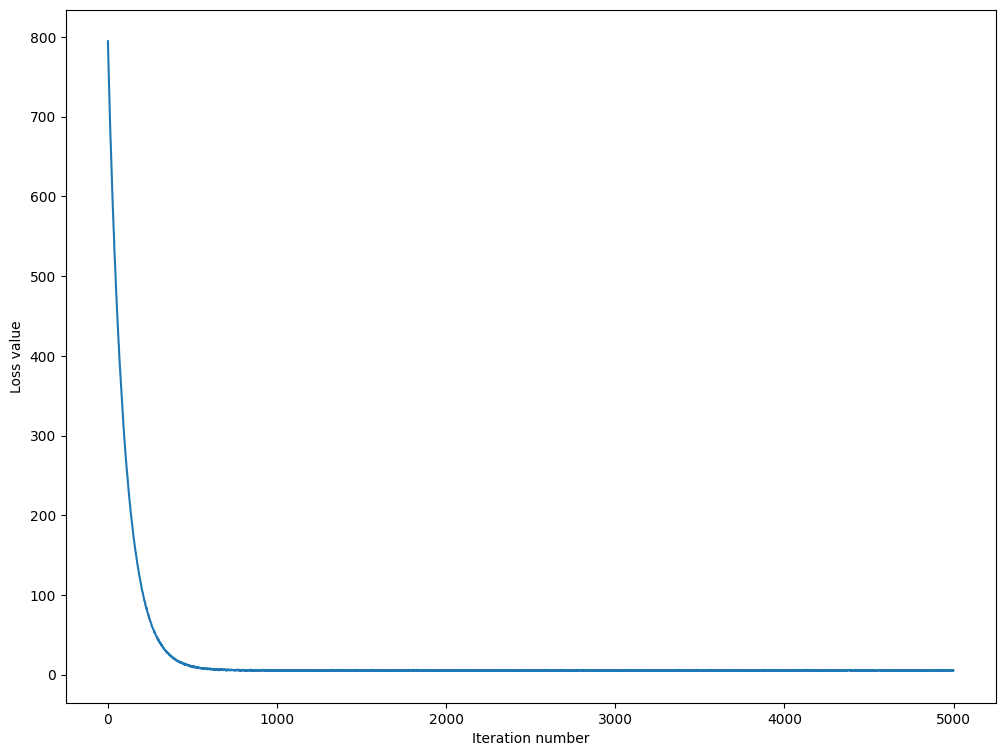

In [15]:
# A useful debugging strategy is to plot the loss as a function of
# iteration number:
plt.plot(loss_hist)
plt.xlabel('Iteration number')
plt.ylabel('Loss value')
plt.show()

**本段解析**

对训练集与验证集计算类别得分，沿类别轴 argmax 得到预测标签，并分别统计准确率。两组指标有助于识别欠拟合与过拟合，但调参依据应是验证结果。

In [16]:
# Write the LinearSVM.predict function and evaluate the performance on both the
# training and validation set
y_train_pred = svm.predict(X_train)
print ('training accuracy: %f' % (np.mean(y_train == y_train_pred), ))
y_val_pred = svm.predict(X_val)
print ('validation accuracy: %f' % (np.mean(y_val == y_val_pred), ))

training accuracy: 0.360041
validation accuracy: 0.368000


**本段解析**

遍历给定学习率与正则化强度，对每组独立初始化并训练模型。记录训练/验证准确率，只按验证准确率更新 best_svm；较强正则化限制权重大小，过大时会压制分类能力。

In [17]:
# Use the validation set to tune hyperparameters (regularization strength and
# learning rate). You should experiment with different ranges for the learning
# rates and regularization strengths; if you are careful you should be able to
# get a classification accuracy of about 0.4 on the validation set.
learning_rates = [1e-7, 5e-6]
regularization_strengths = [5e4, 1e5]

# results is dictionary mapping tuples of the form
# (learning_rate, regularization_strength) to tuples of the form
# (training_accuracy, validation_accuracy). The accuracy is simply the fraction
# of data points that are correctly classified.
results = {}
best_val = -1   # The highest validation accuracy that we have seen so far.
best_svm = None # The LinearSVM object that achieved the highest validation rate.

################################################################################
# TODO:                                                                        #
# Write code that chooses the best hyperparameters by tuning on the validation #
# set. For each combination of hyperparameters, train a linear SVM on the      #
# training set, compute its accuracy on the training and validation sets, and  #
# store these numbers in the results dictionary. In addition, store the best   #
# validation accuracy in best_val and the LinearSVM object that achieves this  #
# accuracy in best_svm.                                                        #
#                                                                              #
# Hint: You should use a small value for num_iters as you develop your         #
# validation code so that the SVMs don't take much time to train; once you are #
# confident that your validation code works, you should rerun the validation   #
# code with a larger value for num_iters.                                      #
################################################################################
for rate in learning_rates:
    for reg in regularization_strengths:
        svm = LinearSVM()
        loss_hist = svm.train(X_train, y_train, learning_rate=rate, reg=reg, num_iters=5000, verbose=True)
        y_train_pred = svm.predict(X_train)
        acc_tr = np.mean(y_train == y_train_pred)
        y_val_pred = svm.predict(X_val)
        acc_val = np.mean(y_val == y_val_pred)
        
        results[(rate, reg)] = (acc_tr, acc_val)
        if acc_val > best_val:
            best_val = acc_val
            best_svm = svm
################################################################################
#                              END OF YOUR CODE                                #
################################################################################
    
# Print out results.
for lr, reg in sorted(results):
    train_accuracy, val_accuracy = results[(lr, reg)]
    print ('lr %e reg %e train accuracy: %f val accuracy: %f' % (
                lr, reg, train_accuracy, val_accuracy))
    
print ('best validation accuracy achieved during cross-validation: %f' % best_val)

iteration 0 / 5000: loss 798.306301
iteration 100 / 5000: loss 289.108560


iteration 200 / 5000: loss 109.345496
iteration 300 / 5000: loss 43.480679


iteration 400 / 5000: loss 19.155196
iteration 500 / 5000: loss 10.534560


iteration 600 / 5000: loss 6.954029
iteration 700 / 5000: loss 6.318234


iteration 800 / 5000: loss 6.202873
iteration 900 / 5000: loss 5.308849


iteration 1000 / 5000: loss 5.215523
iteration 1100 / 5000: loss 5.672536


... (91 outputs left out)

iteration 4400 / 5000: loss 34.349529
iteration 4500 / 5000: loss 24.867456


iteration 4600 / 5000: loss 23.735661
iteration 4700 / 5000: loss 37.393488


iteration 4800 / 5000: loss 34.089680
iteration 4900 / 5000: loss 34.023517


lr 1.000000e-07 reg 5.000000e+04 train accuracy: 0.371837 val accuracy: 0.385000
lr 1.000000e-07 reg 1.000000e+05 train accuracy: 0.347918 val accuracy: 0.362000
lr 5.000000e-06 reg 5.000000e+04 train accuracy: 0.176776 val accuracy: 0.165000
lr 5.000000e-06 reg 1.000000e+05 train accuracy: 0.218633 val accuracy: 0.226000
best validation accuracy achieved during cross-validation: 0.385000


**本段解析**

把超参数转换到 log10 坐标，分别用颜色显示训练和验证准确率。图中每一点代表一次完整配置实验；比较两幅图可以观察正则化和学习率对拟合及泛化的不同影响。

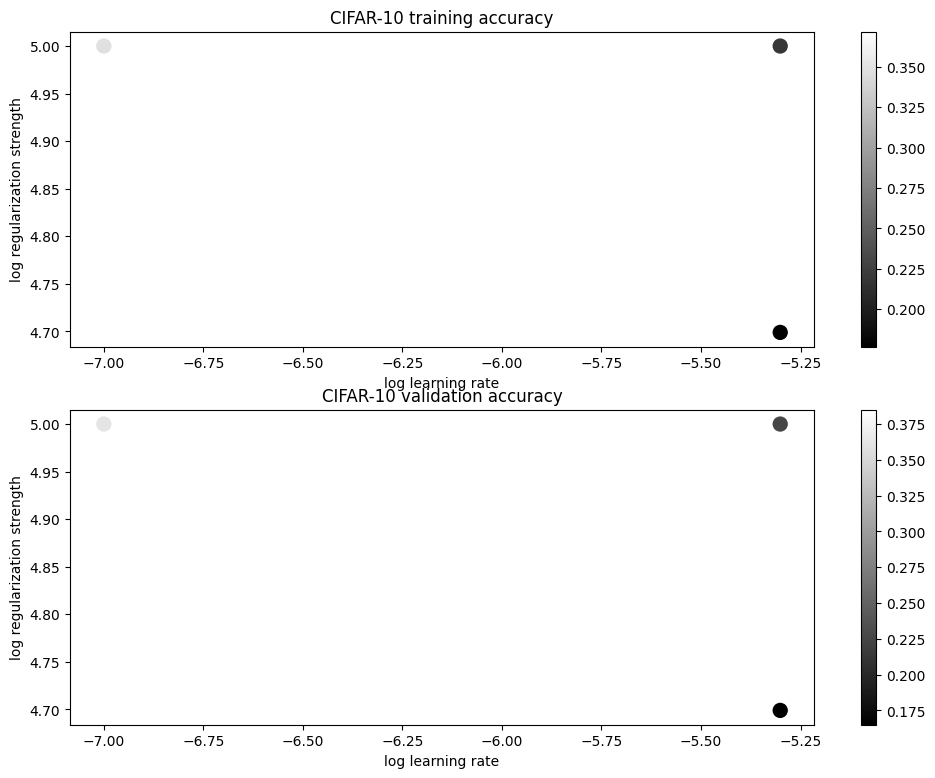

In [18]:
# Visualize the cross-validation results
import math
x_scatter = [math.log10(x[0]) for x in results]
y_scatter = [math.log10(x[1]) for x in results]

# plot training accuracy
marker_size = 100
colors = [results[x][0] for x in results]
plt.subplot(2, 1, 1)
plt.scatter(x_scatter, y_scatter, marker_size, c=colors)
plt.colorbar()
plt.xlabel('log learning rate')
plt.ylabel('log regularization strength')
plt.title('CIFAR-10 training accuracy')

# plot validation accuracy
colors = [results[x][1] for x in results] # default size of markers is 20
plt.subplot(2, 1, 2)
plt.scatter(x_scatter, y_scatter, marker_size, c=colors)
plt.colorbar()
plt.xlabel('log learning rate')
plt.ylabel('log regularization strength')
plt.title('CIFAR-10 validation accuracy')
plt.show()

**本段解析**

模型选择结束后，用 best_svm 对保留测试集作一次预测并计算最终准确率。这里的测试数据量为本题指定的 1000 张，结果不得用于继续选择超参数。

In [19]:
# Evaluate the best svm on test set
y_test_pred = best_svm.predict(X_test)
test_accuracy = np.mean(y_test == y_test_pred)
print ('linear SVM on raw pixels final test set accuracy: %f' % test_accuracy)

linear SVM on raw pixels final test set accuracy: 0.377000


**本段解析**

去掉偏置行，将每类权重重排成 32×32×3 图像，再统一缩放到可显示范围。正负权重分别支持或抑制对应像素模式；线性模板常呈模糊轮廓，不能解释为模型记住了一张真实图像。

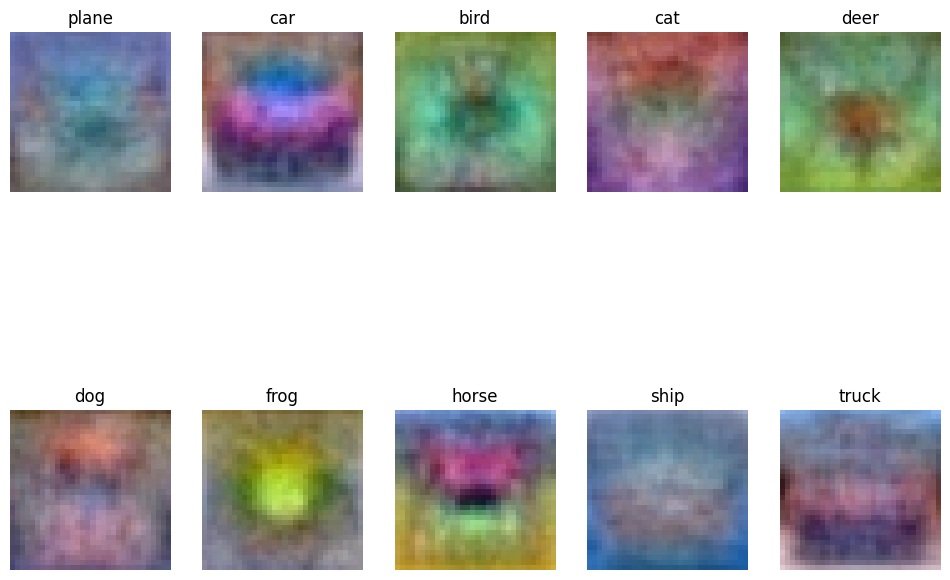

In [20]:
# Visualize the learned weights for each class.
# Depending on your choice of learning rate and regularization strength, these may
# or may not be nice to look at.
w = best_svm.W[:-1,:] # strip out the bias
w = w.reshape(32, 32, 3, 10)
w_min, w_max = np.min(w), np.max(w)
classes = ['plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
for i in range(10):
  plt.subplot(2, 5, i + 1)
    
  # Rescale the weights to be between 0 and 255
  wimg = 255.0 * (w[:, :, :, i].squeeze() - w_min) / (w_max - w_min)
  plt.imshow(wimg.astype('uint8'))
  plt.axis('off')
  plt.title(classes[i])

### Inline Question 2：怎样解释 SVM 权重图？

**我的分析：** 本次权重图中，汽车、卡车等类别能看到居中的横向轮廓，飞机和船的模板带有较明显的蓝色背景倾向，动物类别则更模糊。每一列权重是在像素位置上支持或抑制某类的线性模板，不是某张训练图；同一类物体的姿态、位置和背景差异叠加后，模板容易模糊。这也说明线性模型会利用背景颜色，不能把权重图当成精确的物体定位。

### 保存本次实验
输入是上面实际训练得到的模型、指标和曲线。只保存模型参数与实验结果，不复制原始数据；输出写入本题独立目录，供运行验证核对。

In [21]:
from study_runtime import save_experiment
experiment_metrics = save_experiment(globals(), '002_SVM')


本机实验指标： {'best_val': 0.385, 'test_accuracy': 0.377, 'acc_tr': 0.21863265306122448, 'acc_val': 0.226}


## 实践补充：问题、检查与方法选择

**实际问题。** hinge 在折点不可导，数值梯度个别位置可能跨越折点；需同时查看 margin、绝对误差和扰动步长。训练和验证都很低时，应先检查学习率和输入尺度，不直接增加迭代次数。

**结果解释。** 本次验证 38.5%、测试 37.7%；多组较大学习率配置失败或表现差，仍保留在搜索记录中。

**方法选择。** 原题已包含循环与向量化实现的完整等价对照。再写一个功能相同的矩阵版本没有明确收益，因此不把代码换写法包装为新增算法。

更完整的故障证据见 [问题与解决记录](../003_问题与解决记录.md)。